# T4 — Modelo final: LightGBM + Optuna + walk-forward + SHAP

Entrenado con `src/train.py`. Comparación final vs baselines de T3. Artefactos en `models/` (`model.joblib`, `metrics.json`, `feature_config.json`).

## 1. Resultados: baselines vs final (test 2023–2025)

In [1]:
import json
import pandas as pd
from pathlib import Path

base = json.loads(Path('../models/baseline_metrics.json').read_text())
final = json.loads(Path('../models/metrics.json').read_text())
rows = [
    {'modelo': 'media historica', 'RMSE': round(base['media_historica']['test']['rmse'], 2),
     'MAE': round(base['media_historica']['test']['mae'], 2), 'R2': round(base['media_historica']['test']['r2'], 4)},
    {'modelo': 'linear', 'RMSE': round(base['linear']['test']['rmse'], 2),
     'MAE': round(base['linear']['test']['mae'], 2), 'R2': round(base['linear']['test']['r2'], 4)},
    {'modelo': 'random forest', 'RMSE': round(base['random_forest']['test']['rmse'], 2),
     'MAE': round(base['random_forest']['test']['mae'], 2), 'R2': round(base['random_forest']['test']['r2'], 4)},
    {'modelo': 'lightgbm (final)', 'RMSE': round(final['test']['rmse'], 2),
     'MAE': round(final['test']['mae'], 2), 'R2': round(final['test']['r2'], 4)},
]
print(pd.DataFrame(rows).to_string(index=False))
print()
print('Best params Optuna (val RMSE %.3f):' % final['optuna_best_val_rmse'])
print(json.dumps(final['optuna_best_params'], indent=2))

          modelo  RMSE  MAE    R2
 media historica 10.02 5.02 0.576
          linear  6.06 2.98 0.845
   random forest  5.40 2.27 0.877
lightgbm (final)  4.96 1.85 0.896

Best params Optuna (val RMSE 5.843):
{
  "n_estimators": 580,
  "learning_rate": 0.0116000392113367,
  "num_leaves": 177,
  "min_child_samples": 18,
  "subsample": 0.9181735157825107,
  "colsample_bytree": 0.6915822175408539,
  "reg_lambda": 11.07241742002538
}


## 2. Walk-forward: estabilidad año a año (LightGBM vs XGBoost)

Ventanas expansivas: train ≤2019→test 2020; ≤2020→2021; ≤2021→2022. R² estable y creciente en LightGBM (0,868→0,887→0,897): sin drift alarmante.

In [2]:
wf = final['walk_forward']
wrows = []
for model in ['lightgbm', 'xgboost']:
    for fold in wf[model]:
        fold_name, m = next(iter(fold.items()))
        wrows.append({'modelo': model, 'vuelta': fold_name,
                      'RMSE': round(m['rmse'], 2), 'R2': round(m['r2'], 4),
                      'n': m['n']})
print(pd.DataFrame(wrows).to_string(index=False))

  modelo                    vuelta  RMSE     R2      n
lightgbm fold_train<=2019_test2020  5.51 0.8676 117651
lightgbm fold_train<=2020_test2021  5.14 0.8869  94130
lightgbm fold_train<=2021_test2022  4.94 0.8970  70644
 xgboost fold_train<=2019_test2020  6.04 0.8406 117651
 xgboost fold_train<=2020_test2021  5.63 0.8642  94130
 xgboost fold_train<=2021_test2022  5.41 0.8763  70644


## 3. Predicho vs real + residuos por año (test)

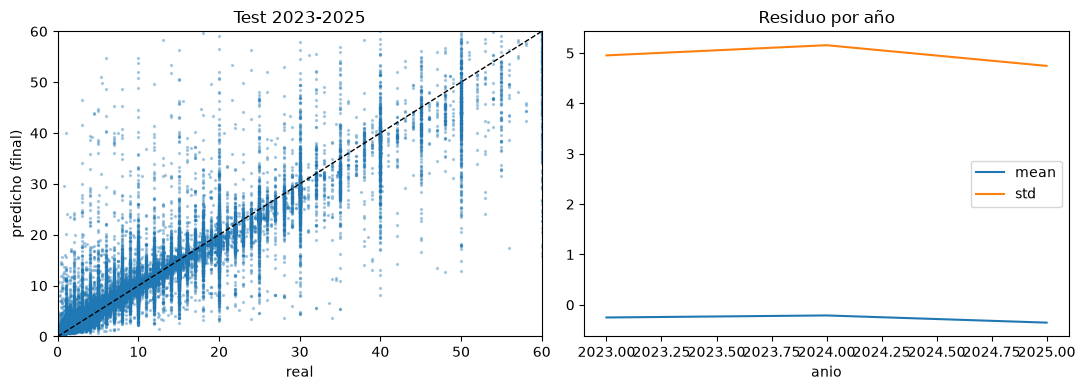

error abs medio: 1.85 | residuo medio: -0.272


In [3]:
import matplotlib.pyplot as plt
pred = pd.read_csv('../models/test_predictions.csv')
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(pred.y_true, pred.y_pred, s=2, alpha=.3)
ax[0].plot([0, 60], [0, 60], 'k--', lw=1)
ax[0].set_xlabel('real'); ax[0].set_ylabel('predicho (final)')
ax[0].set_title('Test 2023-2025'); ax[0].set_xlim(0, 60); ax[0].set_ylim(0, 60)
pred['res'] = pred.y_pred - pred.y_true
pred.groupby('anio')['res'].agg(['mean', 'std']).plot(ax=ax[1])
ax[1].set_title('Residuo por año')
plt.tight_layout(); plt.show()
print('error abs medio:', pred['res'].abs().mean().round(2),  '| residuo medio:', pred['res'].mean().round(3))

## 4. Importancia SHAP (modelo final sobre test)

Dominan las features históricas (r_roll3, r_lag1, encoding de cultivo): el rendimiento se autocorrelaciona. `area_sembrada_log` aporta señal marginal; `hist_len` (profundidad de la serie) también.

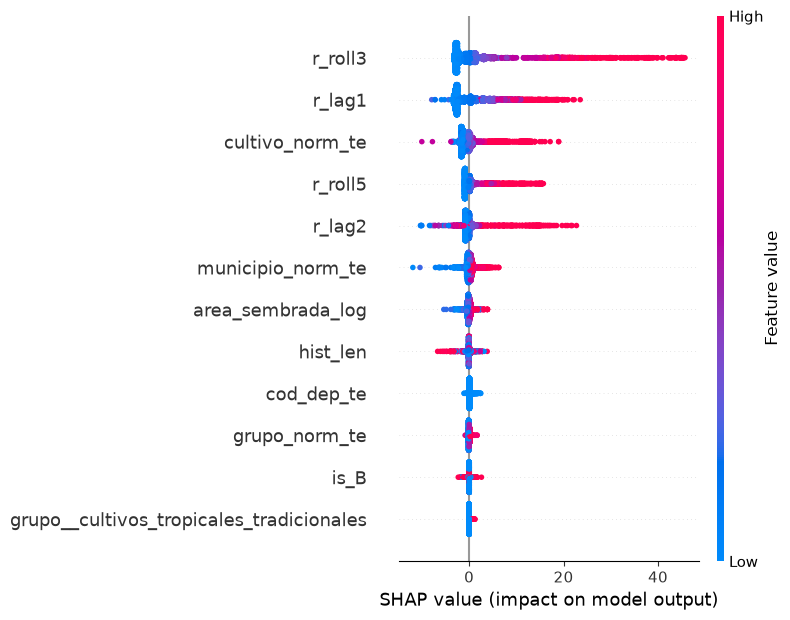

In [4]:
import joblib, shap, sys
sys.path.insert(0, str(Path('../src')))
from features import build_features, load_clean, prepare_xy

df = load_clean()
m = build_features(df)
splits, _ = prepare_xy(m, train_end=2020, val_end=2022)
Xte = splits['test'][0]
model = joblib.load('../models/model.joblib')
explainer = shap.TreeExplainer(model)
sv = explainer.shap_values(Xte.head(5000))
shap.summary_plot(sv, Xte.head(5000), show=False, max_display=12)
plt.tight_layout(); plt.show()

## Conclusiones T4

- LightGBM final: **test RMSE 4,96 / MAE 1,85 / R² 0,896 / MedAPE 10,3%** (mejora RF 5,40/0,877).
- Walk-forward estable (R² 0,87–0,90 en 3 años): el modelo no depende de un año con suerte.
- XGBoost gana en nada: queda fuera del deploy (se documenta la comparación).
- SHAP: la historia manda (lags/rolling + encoding). Si el modelo se usa para municipios nuevos (sin historia), rendimiento degradado → documentado en README.
- Siguiente paso (T5): API FastAPI + Docker reutilizando `feature_config.json` y `model.joblib`; endpoint `/predict` con un intervalo de predicción.